# Data Mining — Linear Regression — Mini-Project 1

**Course:** [CSEN911] Data Mining (Winter 2026)  
**Instructor:** Dr. Ayman Alserafi  
**Due:** 17 October 2026, 11:59 PM

**Dataset:** `energy_data.csv`  



***Edit this cell with your name(s), tutorial number(s) and ID(s)***

---

Name: Michael Wael William

ID: 61-3618

Tutorial:T02

---

Name: Aly Hassan

ID:61-17564

Tutorial: T02

---


The dataset contains building-level energy readings and contextual attributes.

Each row represents a building observation. Columns include:

<div style="font-size:20px;">

| **Column** | **Description** |
|-------------|-----------------|
| **Building_ID** | Unique identifier for each building record. Used to distinguish one building entry from another. |
| **Building_Type** | Category describing the primary use of the building (e.g., Residential, Commercial, Industrial, Educational, etc.). |
| **Governorate** | The administrative region (governorate) where the building is located (e.g., Cairo, Giza, Alexandria). |
| **Neighborhood** | The smaller district or local area within the governorate where the building is located. |
| **Day_of_Week** | The day on which the energy consumption measurement was recorded (e.g., Sunday, Monday, etc.). |
| **Occupancy_Level** | The relative number of occupants or activity level in the building, typically categorized as *Low*, *Medium*, or *High*. |
| **Appliances_Usage_Level** | Indicates how intensively appliances are used in the building *Low*, *Medium*, or *High*. |
| **SquareFootage** | The total floor area of the building (numeric). Serves as a proxy for building size, often influencing energy usage. |
| **Last_Maintenance_Date** | The date of the last maintainance done on the building. |
| **Average_Temperature** | The average ambient temperature (in °C) recorded during the data period. |
| **Energy_Consumption** | The total energy used by the building, typically measured in kilowatt-hours (kWh).|

</div>


## Importing Libraries & Dataset

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    df = pd.read_csv('energy_data.csv')
except:
    df = pd.read_csv('https://raw.githubusercontent.com/GUC-DM/W2026/refs/heads/main/data/energy_data.csv')

df.head()

,Building_ID,Building_Type,Governorate,Neighborhood,Day_of_Week,Occupancy_Level,Appliances_Usage_Level,SquareFootage,Last_Maintenance_Date,Average_Temperature,Energy_Consumption
0,BLD-1000-UD,Residential,Alexandria,Smouha,WeDnesday,High,Low,7063m2,2020-01-01,28.61,2713.95 kWh
1,BLD-1001-AX,Commercial,Giza,+Mohandessin14,tuesDAY,High,High,44372m2,2022-02-24,NaN,5744.99 kWh
2,BLD-1002-IH,Industrial,Cairo,New Cairo,SunDay,Medium,Low,19255,2021-02-22,37.88,4101.24 kWh
3,BLD-1003-HE,NaN,NaN,+92Dokki,TuesDay,Low,High,13265,2023-07-30,35.06,3009.14 kWh
4,BLD-1004-XD,Commercial,Alexandria,Smouha,Monday,Low,Low,13375,2022-08-12,28.82,3279.17 kWh


## Data Inspection

Perform data inspection tasks here (recommended for data understanding).

In [59]:
# Size of the dataset (rows, columns)
print(df.shape)

# Column types and the number of non-empty values each has
df.info()

# Missing values per column
print(df.isnull().sum())

# Duplicate rows
print("Duplicates:", df.duplicated().sum())

# statistics for number columns
print(df.describe())

# view any unorganized values in the text columns
for col in ['Building_Type', 'Governorate', 'Neighborhood', 'Day_of_Week',
            'Occupancy_Level', 'Appliances_Usage_Level']:
    print(col, df[col].unique())

(1100, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Building_ID             1100 non-null   object 
 1   Building_Type           990 non-null    object 
 2   Governorate             873 non-null    object 
 3   Neighborhood            1100 non-null   object 
 4   Day_of_Week             1100 non-null   object 
 5   Occupancy_Level         1100 non-null   object 
 6   Appliances_Usage_Level  1100 non-null   object 
 7   SquareFootage           1100 non-null   object 
 8   Last_Maintenance_Date   1100 non-null   object 
 9   Average_Temperature     990 non-null    float64
 10  Energy_Consumption      1100 non-null   object 
dtypes: float64(1), object(10)
memory usage: 94.7+ KB
Building_ID                 0
Building_Type             110
Governorate               227
Neighborhood                0
Day_of_Week        

## Data Pre-Processing & Cleaning

_Apply any data preprocessing and/or feature engineering below. Show/output the changes to the dataset._

In [60]:
# Work on a copy in oreder to perserve the original
data = df.copy()

# Drop Building_ID
data = data.drop(columns=['Building_ID'])

# Fix Day_of_Week capitalisation
data['Day_of_Week'] = data['Day_of_Week'].str.strip().str.capitalize()

# Clean Neighborhood: remove symbols and numbers
data['Neighborhood'] = data['Neighborhood'].str.replace(r'[^A-Za-z ]', '', regex=True).str.strip()

# Change SquareFootage into a number
data['SquareFootage'] = data['SquareFootage'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float)

# Change Energy_Consumption into a number
data['Energy_Consumption'] = data['Energy_Consumption'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float)

#  Fill missing Governorate using the neighborhood
gov_map = {
    'Smouha': 'Alexandria', 'Gleem': 'Alexandria',
    'Dokki': 'Giza', 'Mohandessin': 'Giza',
    'New Cairo': 'Cairo', 'Heliopolis': 'Cairo', 'Maadi': 'Cairo'
}
data['Governorate'] = data['Governorate'].fillna(data['Neighborhood'].map(gov_map))

# Fill missing Building_Type with the most common type
data['Building_Type'] = data['Building_Type'].fillna(data['Building_Type'].mode()[0])

# Fill missing temperature with the median
data['Average_Temperature'] = data['Average_Temperature'].fillna(data['Average_Temperature'].median())

# Turn the maintenance date into "days since last maintenance"
data['Last_Maintenance_Date'] = pd.to_datetime(data['Last_Maintenance_Date'])
latest = data['Last_Maintenance_Date'].max()
data['Days_Since_Maintenance'] = (latest - data['Last_Maintenance_Date']).dt.days

# Display changes
print(data.head())
print("\nMissing values after cleaning:\n", data.isnull().sum())
print("\nNeighborhoods:", data['Neighborhood'].unique())
print("Days:", data['Day_of_Week'].unique())
data.info()

  Building_Type Governorate Neighborhood Day_of_Week Occupancy_Level  \
0   Residential  Alexandria       Smouha   Wednesday            High   
1    Commercial        Giza  Mohandessin     Tuesday            High   
2    Industrial       Cairo    New Cairo      Sunday          Medium   
3   Residential        Giza        Dokki     Tuesday             Low   
4    Commercial  Alexandria       Smouha      Monday             Low   

  Appliances_Usage_Level  SquareFootage Last_Maintenance_Date  \
0                    Low         7063.0            2020-01-01   
1                   High        44372.0            2022-02-24   
2                    Low        19255.0            2021-02-22   
3                   High        13265.0            2023-07-30   
4                    Low        13375.0            2022-08-12   

   Average_Temperature  Energy_Consumption  Days_Since_Maintenance  
0                28.61             2713.95                    1826  
1                35.26             574

## Exploratory Data Analysis

**Q1:** What are the most popular neighborhoods? plot all and order them on the graph (mention top 3)

**Visualization**

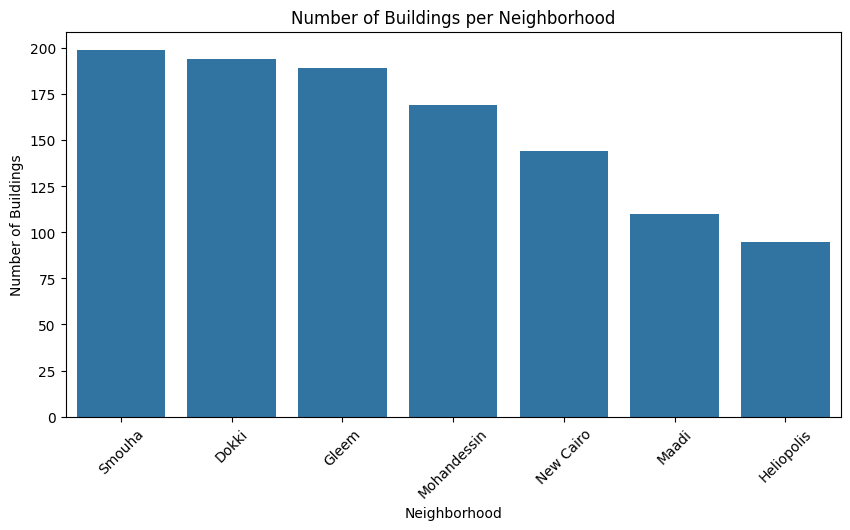

Neighborhood
Smouha         199
Dokki          194
Gleem          189
Mohandessin    169
New Cairo      144
Maadi          110
Heliopolis      95
Name: count, dtype: int64


In [61]:
# Count how many buildings are in each neighborhood,
# sort from most to least
order = data['Neighborhood'].value_counts().index

# Make a new blank figure, 10 wide and 5 tall
plt.figure(figsize=(10, 5))

# chart: one bar per neighborhood, bar height equals number of buildings
# order=order makes the bars appear from biggest to smallest
sns.countplot(data=data, x='Neighborhood', order=order)

# Add a title at the top of the chart
plt.title('Number of Buildings per Neighborhood')

# Label the x-axis
plt.xlabel('Neighborhood')

# Label the y-axis
plt.ylabel('Number of Buildings')

# Tilt the neighborhood names 45 degrees so they don't overlap
plt.xticks(rotation=45)

# Display the chart
plt.show()

# Print the exact count for each neighborhood
print(data['Neighborhood'].value_counts())

**Answer for Q1:** _Your answer here_

**Q2:** Show the distribution of the energy consumption of each Building type.

Which type have the widest distribution of energy consumption?

Which (on average) has the highest consumption?.

**Visualization**

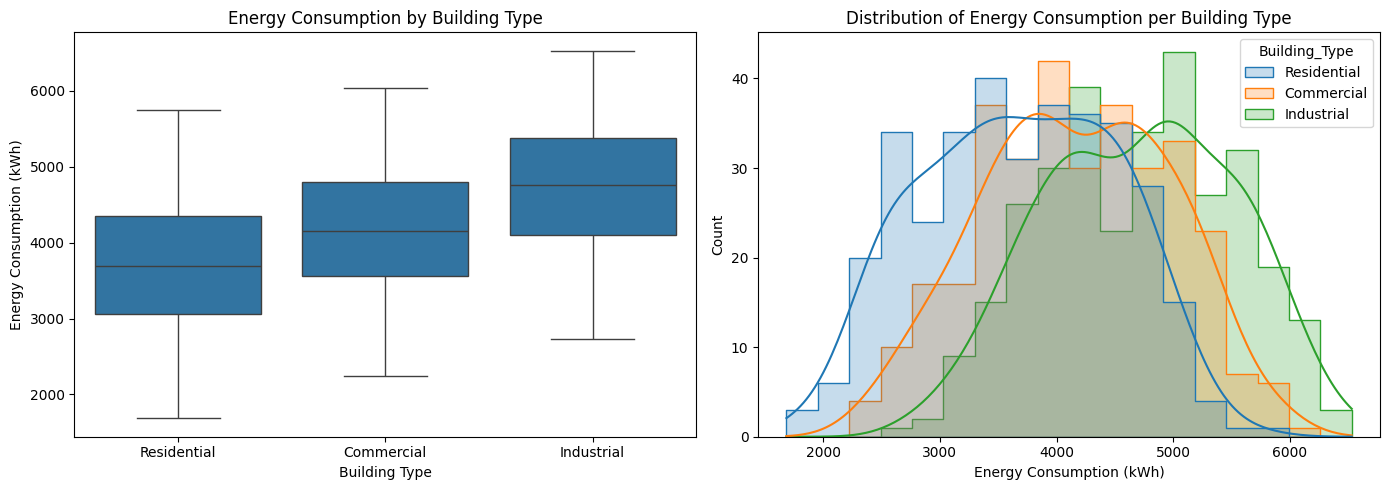

                  mean   median     std      min      max    range      IQR
Building_Type                                                              
Commercial     4170.37  4157.81  809.70  2241.96  6042.56  3800.60  1244.06
Industrial     4708.42  4760.64  818.16  2724.82  6530.60  3805.78  1272.68
Residential    3679.40  3694.52  833.34  1683.95  5746.40  4062.45  1285.25


In [62]:

# In cleaning I filled 110 missing types with "Residential", which would
# unfairly stretch the Residential group. So i kept only the rows where
# the ORIGINAL dataset (df) had a building type
known = df['Building_Type'].notna()
q2 = data[known]

# Create one figure with two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left chart: boxplot
# - the box = the middle 50% of buildings (taller box = more spread)
# - the line inside the box = the median (middle value)
# - the whiskers = the normal range; dots beyond them = outliers
sns.boxplot(data=q2, x='Building_Type', y='Energy_Consumption', ax=axes[0])
axes[0].set_title('Energy Consumption by Building Type')
axes[0].set_xlabel('Building Type')
axes[0].set_ylabel('Energy Consumption (kWh)')

# Right chart: histogram with a smooth curve for each building type
# This shows the SHAPE of each distribution: where values bunch up
# and how far they spread
sns.histplot(data=q2, x='Energy_Consumption', hue='Building_Type',
             kde=True, element='step', ax=axes[1])
axes[1].set_title('Distribution of Energy Consumption per Building Type')
axes[1].set_xlabel('Energy Consumption (kWh)')

# Stop the two charts from overlapping, then show them
plt.tight_layout()
plt.show()

# groups numbers per building type
groups = q2.groupby('Building_Type')['Energy_Consumption']
summary = groups.agg(['mean', 'median', 'std', 'min', 'max'])  # average, middle value, spread, lowest, highest
summary['range'] = summary['max'] - summary['min']             # total spread (highest minus lowest)
summary['IQR'] = groups.quantile(0.75) - groups.quantile(0.25)  # spread of the middle 50% (ignores extremes)
print(summary.round(2))

**Answer for Q2:** _Your answer here_

**Q3:** How does the building size affect energy consumption?

**Visualization**

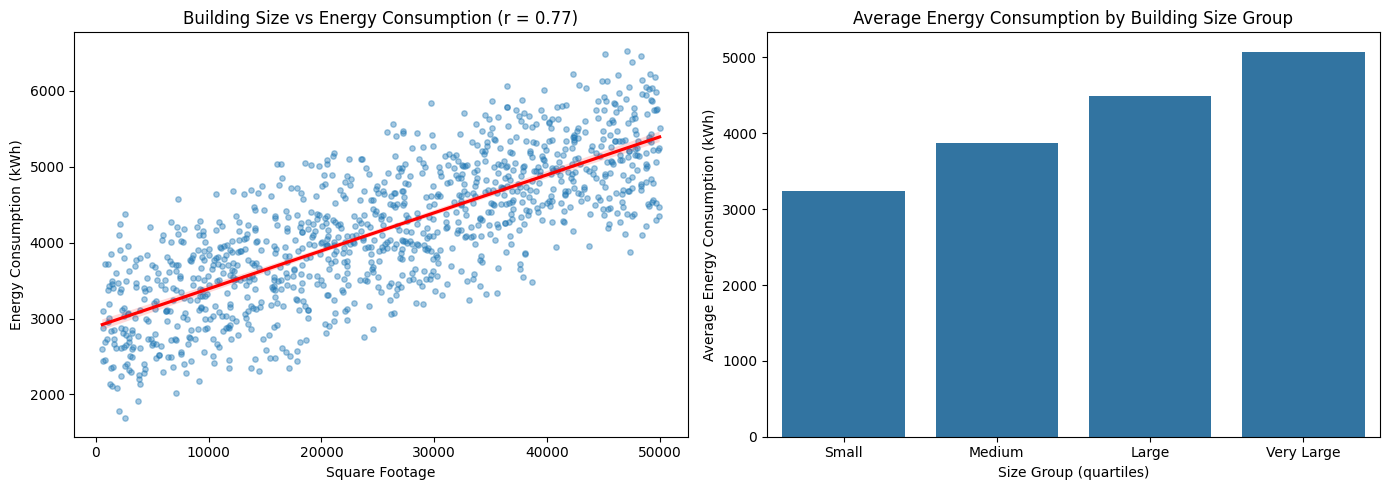

Correlation (r): 0.771
Slope: 0.0500 kWh per unit of area

Average energy per size group:
SquareFootage
Small         3239.8
Medium        3868.5
Large         4486.9
Very Large    5077.6
Name: Energy_Consumption, dtype: float64


In [63]:
# Correlation measures how strongly two columns move together:
# +1 = perfectly together, 0 = no relationship, -1 = perfectly opposite
corr = data['SquareFootage'].corr(data['Energy_Consumption'])

# Fit a straight line (energy = slope * size + intercept)
slope, intercept = np.polyfit(data['SquareFootage'], data['Energy_Consumption'], 1)

# Split buildings into 4 equal-sized groups by size (smallest 25%, next 25%, ...)
# and get the average energy of each group
size_groups = pd.qcut(data['SquareFootage'], 4,
                      labels=['Small', 'Medium', 'Large', 'Very Large'])
group_means = data.groupby(size_groups, observed=True)['Energy_Consumption'].mean()

# Create one figure with two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left chart: scatter plot with the best-fit line
# Each dot is one building; the red line shows the overall trend
sns.regplot(data=data, x='SquareFootage', y='Energy_Consumption',
            scatter_kws={'alpha': 0.4, 's': 15},
            line_kws={'color': 'red'}, ax=axes[0])
axes[0].set_title(f'Building Size vs Energy Consumption (r = {corr:.2f})')
axes[0].set_xlabel('Square Footage')
axes[0].set_ylabel('Energy Consumption (kWh)')

# Right chart: average energy for each size group
# Makes the trend easy to read at a glance
sns.barplot(x=group_means.index, y=group_means.values, ax=axes[1])
axes[1].set_title('Average Energy Consumption by Building Size Group')
axes[1].set_xlabel('Size Group (quartiles)')
axes[1].set_ylabel('Average Energy Consumption (kWh)')

plt.tight_layout()
plt.show()

# Print the key numbers
print(f'Correlation (r): {corr:.3f}')
print(f'Slope: {slope:.4f} kWh per unit of area')
print('\nAverage energy per size group:')
print(group_means.round(1))

**Answer for Q3:** _Your answer here_

**Q4:** Do buildings consume more energy if not maintained frequently?

**Visualization**

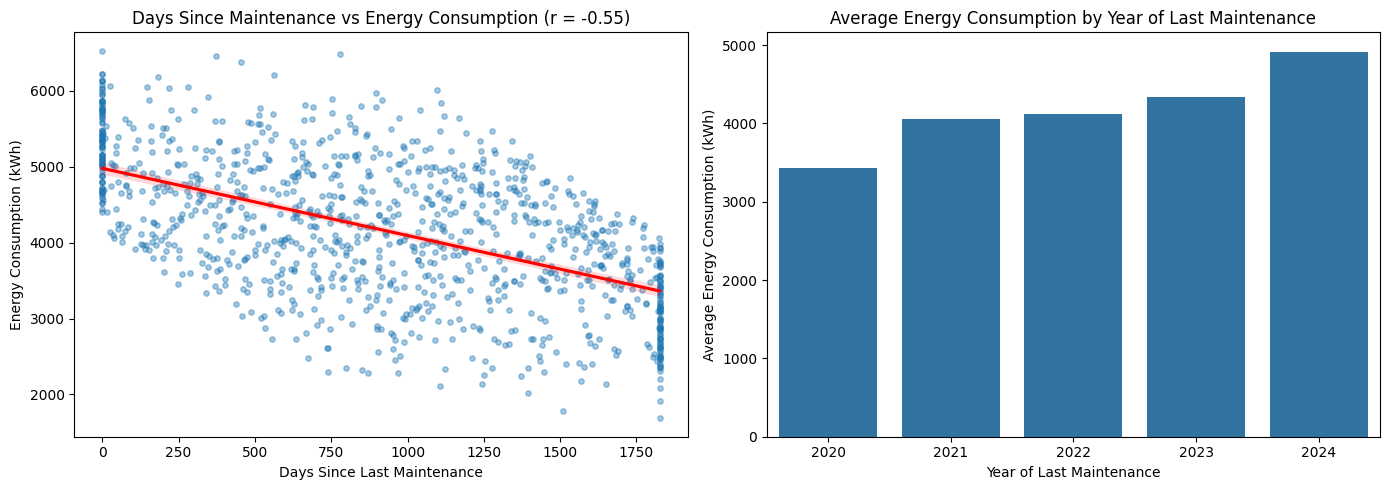

Correlation (r): -0.551
Slope: -0.885 kWh per day since maintenance

Average energy by year of last maintenance:
Last_Maintenance_Date
2020    3433.5
2021    4059.2
2022    4125.7
2023    4337.4
2024    4916.9
Name: Energy_Consumption, dtype: float64

Correlation between days since maintenance and size: -0.421


In [64]:
# Correlation between "days since last maintenance" and energy use
# Positive = less maintenance MORE energy; negative = less maintenance less energy
corr = data['Days_Since_Maintenance'].corr(data['Energy_Consumption'])

# Fit a straight line to get the slope,change in energy per extra day without maintenance
slope, intercept = np.polyfit(data['Days_Since_Maintenance'], data['Energy_Consumption'], 1)

# Average energy per year of last maintenance
maint_year = data['Last_Maintenance_Date'].dt.year
year_means = data.groupby(maint_year)['Energy_Consumption'].mean()

# Create one figure with two charts side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left chart: scatter plot with the best-fit line
# Each dot is one building; the red line shows the overall trend
sns.regplot(data=data, x='Days_Since_Maintenance', y='Energy_Consumption',
            scatter_kws={'alpha': 0.4, 's': 15},
            line_kws={'color': 'red'}, ax=axes[0])
axes[0].set_title(f'Days Since Maintenance vs Energy Consumption (r = {corr:.2f})')
axes[0].set_xlabel('Days Since Last Maintenance')
axes[0].set_ylabel('Energy Consumption (kWh)')

# Right chart: average energy grouped by the year of last maintenance
sns.barplot(x=year_means.index, y=year_means.values, ax=axes[1])
axes[1].set_title('Average Energy Consumption by Year of Last Maintenance')
axes[1].set_xlabel('Year of Last Maintenance')
axes[1].set_ylabel('Average Energy Consumption (kWh)')

plt.tight_layout()
plt.show()

# Display the key numbers
print(f'Correlation (r): {corr:.3f}')
print(f'Slope: {slope:.3f} kWh per day since maintenance')
print('\nAverage energy by year of last maintenance:')
print(year_means.round(1))

# Check if the recently maintained buildings also bigger
print(f"\nCorrelation between days since maintenance and size: "
      f"{data['Days_Since_Maintenance'].corr(data['SquareFootage']):.3f}")

**Answer for Q4:** _Your answer here_

**Q5:** Are all the numerical variables normally distributed, or is there any skewness?

**Visualization**

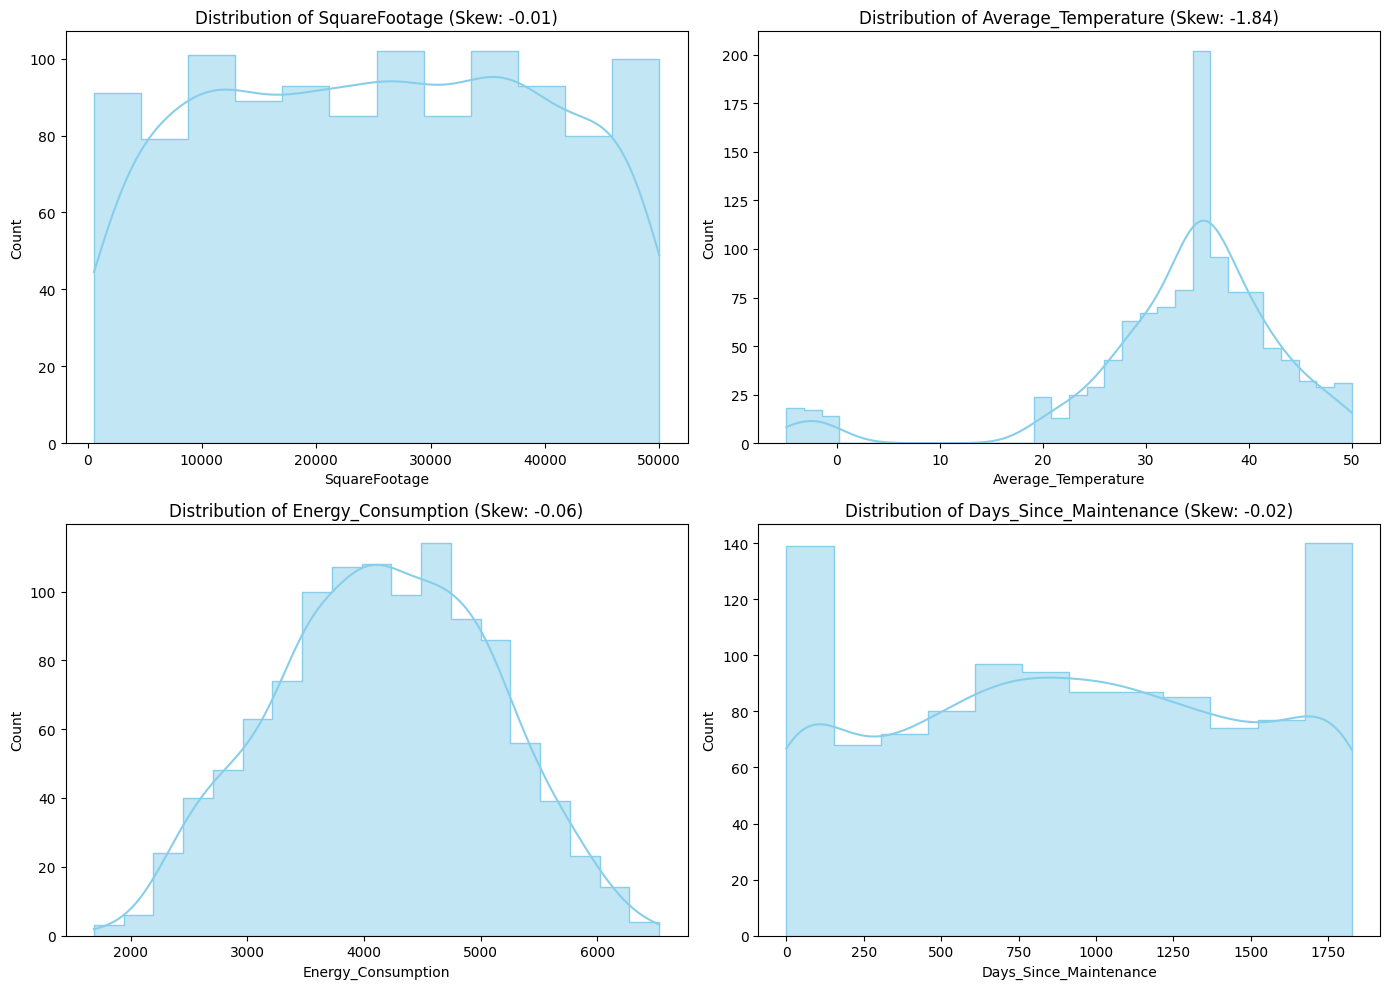

Skewness of numerical variables:
SquareFootage              -0.01  -> roughly symmetric
Average_Temperature        -1.84  -> highly skewed
Energy_Consumption         -0.06  -> roughly symmetric
Days_Since_Maintenance     -0.02  -> roughly symmetric


In [65]:
# The numerical columns to check
num_cols = ['SquareFootage', 'Average_Temperature', 'Energy_Consumption', 'Days_Since_Maintenance']

# One figure with a 2x2 grid of charts (one chart per column)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()   # turn the 2x2 grid into a simple list of 4 charts

for i, col in enumerate(num_cols):
    # Skewness: 0 = perfectly symmetric, negative = tail on the left, positive = tail on the right
    skew_val = data[col].skew()

    # Histogram (bars) + KDE (smooth curve) to show the shape of the distribution
    sns.histplot(data=data, x=col, kde=True, element='step', color='skyblue', ax=axes[i])
    axes[i].set_title(f'Distribution of {col} (Skew: {skew_val:.2f})')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

plt.tight_layout()   # stop titles and labels from overlapping
plt.show()

# Print each column's skewness and what it means
# Rule of thumb: |skew| < 0.5 = roughly symmetric, 0.5 to 1 = moderately skewed, > 1 = highly skewed
print("Skewness of numerical variables:")
for col in num_cols:
    s = data[col].skew()
    if abs(s) < 0.5:
        label = 'roughly symmetric'
    elif abs(s) < 1:
        label = 'moderately skewed'
    else:
        label = 'highly skewed'
    print(f'{col:25s} {s:6.2f}  -> {label}')

**Answer for Q5:** _Your answer here_

**Q6:** What is multicollinearity? And why is it a problem for linear regression? Does this problem exist in this
dataset?

**Visualization**

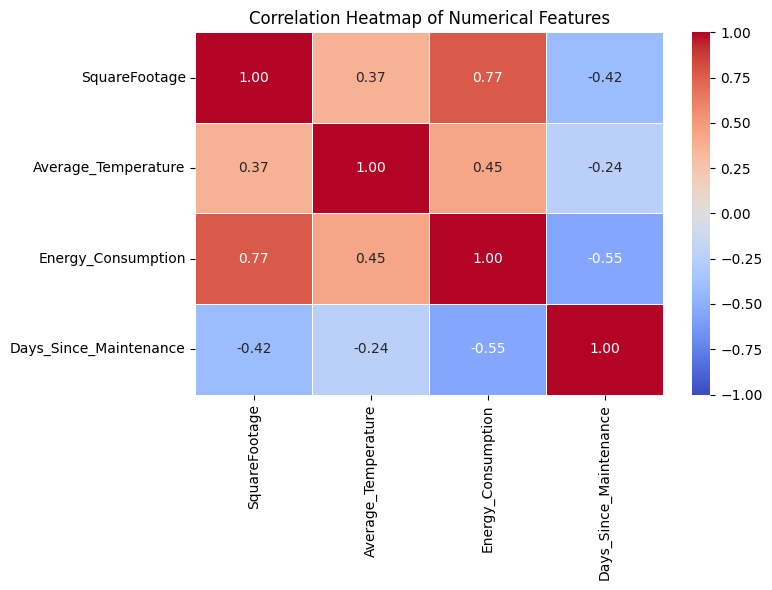

Exact Correlation Matrix Values:
                        SquareFootage  Average_Temperature  \
SquareFootage                1.000000             0.367444   
Average_Temperature          0.367444             1.000000   
Energy_Consumption           0.770765             0.445190   
Days_Since_Maintenance      -0.420811            -0.242132   

                        Energy_Consumption  Days_Since_Maintenance  
SquareFootage                     0.770765               -0.420811  
Average_Temperature               0.445190               -0.242132  
Energy_Consumption                1.000000               -0.551404  
Days_Since_Maintenance           -0.551404                1.000000  


In [66]:
# Select only the numerical columns from our cleaned dataframe to analyze their correlations
num_df = data.select_dtypes(include=[np.number])

# Compute the pairwise correlation matrix for all selected numerical variables
corr_matrix = num_df.corr()

# Create a new figure window with a specific width and height (8 by 6 inches)
plt.figure(figsize=(8, 6))

# Generate a heatmap to visualize the correlation matrix, with numbers annotated inside cells,
# using a diverging color map ('coolwarm'), formatted to 2 decimal places, and fixing color limits from -1 to 1
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=0.5)

# Set the title at the top of the heatmap plot
plt.title('Correlation Heatmap of Numerical Features')

# Adjust layout automatically to ensure labels, ticks, and titles fit properly without cropping
plt.tight_layout()

# Render and display the generated heatmap visualization
plt.show()

# Print the exact numerical correlation values in the console output for thorough inspection
print("Exact Correlation Matrix Values:")
print(corr_matrix)

**Answer for Q6:** _Your answer here_

## Data Preparation for Modelling

_Apply any additional data preparation steps needed before modelling below. Show/output the changes to the dataset._

In [67]:
# Import the train_test_split function from scikit-learn to split our data for machine learning
from sklearn.model_selection import train_test_split

# Define the list of independent feature columns we want to use to predict energy consumption
feature_cols = [
    'Building_Type', 'Governorate', 'Neighborhood', 'Day_of_Week',
    'Occupancy_Level', 'Appliances_Usage_Level', 'SquareFootage',
    'Average_Temperature', 'Days_Since_Maintenance'
]

# Extract the feature matrix (X) by filtering our cleaned dataframe with the selected feature columns
X = data[feature_cols]

# Extract the target variable (y) that the model needs to learn to predict (Energy Consumption)
y = data['Energy_Consumption']

# Convert categorical text columns into numeric dummy/indicator variables using pandas get_dummies,
# and set drop_first=True to drop the first category of each variable and prevent multicollinearity (dummy variable trap)
X_encoded = pd.get_dummies(X, drop_first=True)

# Split the dataset into training sets (80%) and testing sets (20%) using a fixed random_state for reproducible results
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# Print out the dimensions (number of rows and columns) of the training and testing feature and target sets
print(f"Training features shape (X_train): {X_train.shape}")
print(f"Testing features shape (X_test): {X_test.shape}")
print(f"Training target shape (y_train): {y_train.shape}")
print(f"Testing target shape (y_test): {y_test.shape}")

# Display a preview of the newly encoded feature matrix columns to show the effect of categorical transformation
print("\nFirst few rows and columns of the encoded feature dataset:")
display(X_encoded.head())

Training features shape (X_train): (880, 23)
Testing features shape (X_test): (220, 23)
Training target shape (y_train): (880,)
Testing target shape (y_test): (220,)

First few rows and columns of the encoded feature dataset:


,SquareFootage,Average_Temperature,Days_Since_Maintenance,Building_Type_Industrial,Building_Type_Residential,Governorate_Cairo,Governorate_Giza,Neighborhood_Gleem,Neighborhood_Heliopolis,Neighborhood_Maadi,...,Day_of_Week_Monday,Day_of_Week_Saturday,Day_of_Week_Sunday,Day_of_Week_Thursday,Day_of_Week_Tuesday,Day_of_Week_Wednesday,Occupancy_Level_Low,Occupancy_Level_Medium,Appliances_Usage_Level_Low,Appliances_Usage_Level_Medium
0,7063.0,28.61,1826,False,True,False,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False
1,44372.0,35.26,1041,False,False,False,True,False,False,False,...,False,False,False,False,True,False,False,False,False,False
2,19255.0,37.88,1408,True,False,True,False,False,False,False,...,False,False,True,False,False,False,False,True,True,False
3,13265.0,35.06,520,False,True,False,True,False,False,False,...,False,False,False,False,True,False,True,False,False,False
4,13375.0,28.82,872,False,False,False,False,False,False,False,...,True,False,False,False,False,False,True,False,True,False


## Modelling

_Apply the linear regression model below._

In [68]:
# Import the LinearRegression model class from scikit-learn
from sklearn.linear_model import LinearRegression

# Initialize an instance of the Linear Regression model and store it in a variable
model = LinearRegression()

# Train (fit) the linear regression model using the encoded training features and the training target values (Energy Consumption)
model.fit(X_train, y_train)

# Generate energy consumption predictions on our unseen testing feature set (X_test)
y_pred = model.predict(X_test)

# Print a confirmation message indicating that the model has been successfully trained and evaluated
print("Linear Regression model training completed successfully!")

# Display the learned intercept (the base value of energy consumption when all features are zero)
print(f"Model Intercept: {model.intercept_:.4f}")

# Display the number of learned regression coefficients (weights) corresponding to each feature
print(f"Number of Feature Coefficients: {len(model.coef_)}")

# Display the first few predicted energy consumption values alongside the actual values for comparison
comparison_df = pd.DataFrame({'Actual Energy': y_test.values[:5], 'Predicted Energy': y_pred[:5]})
print("\nComparison of First 5 Actual vs. Predicted Values:")
display(comparison_df)


Linear Regression model training completed successfully!
Model Intercept: 3612.8784
Number of Feature Coefficients: 23

Comparison of First 5 Actual vs. Predicted Values:


,Actual Energy,Predicted Energy
0,3708.08,3802.228620
1,3372.20,3283.260236
2,5023.85,4976.292818
3,3314.91,3316.909597
4,3984.20,3896.917976


## Model Evaluation

Evaluate the model you applied.

=== Linear Regression Model Evaluation Metrics ===
R-squared (R²): 0.9451
Root Mean Squared Error (RMSE): 216.1430 kWh
Mean Absolute Error (MAE): 159.0396 kWh


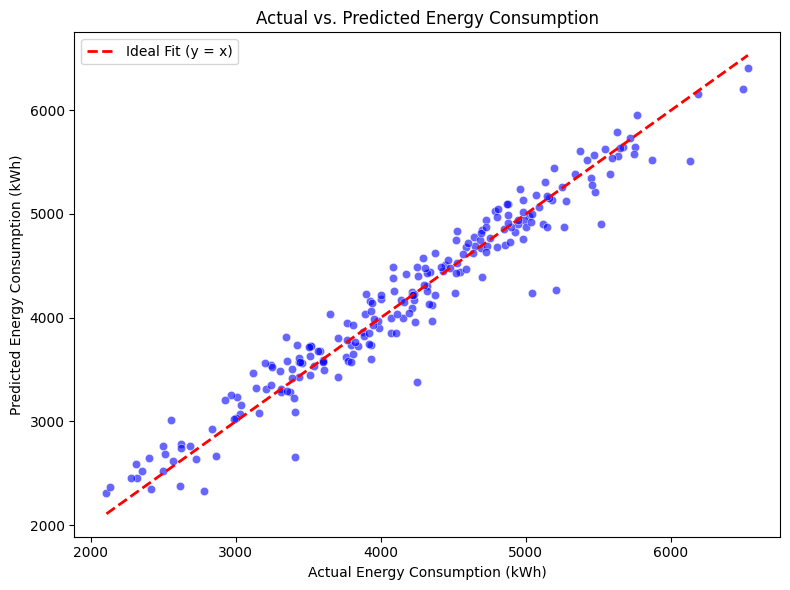

In [69]:
# Import the LinearRegression model class from scikit-learn
from sklearn.linear_model import LinearRegression

# Import regression performance metrics to evaluate our model's accuracy:
# mean_squared_error (to compute MSE/RMSE), mean_absolute_error (MAE), and r2_score (R-squared)
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Initialize an instance of the Linear Regression model
lr_model = LinearRegression()

# Train (fit) the linear regression model using our training feature set (X_train) and training target values (y_train)
lr_model.fit(X_train, y_train)

# Generate energy consumption predictions on the unseen test feature set (X_test)
y_pred = lr_model.predict(X_test)

# Calculate the R-squared (Coefficient of Determination) score to measure the proportion of variance explained by the model
r2 = r2_score(y_test, y_pred)

# Calculate the Root Mean Squared Error (RMSE) by taking the square root of the Mean Squared Error
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Calculate the Mean Absolute Error (MAE) to find the average magnitude of absolute errors in kWh
mae = mean_absolute_error(y_test, y_pred)

# Print out the evaluation metrics clearly in the console output
print("=== Linear Regression Model Evaluation Metrics ===")
print(f"R-squared (R²): {r2:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} kWh")
print(f"Mean Absolute Error (MAE): {mae:.4f} kWh")

# Create a visualization plot comparing Actual vs. Predicted Energy Consumption values
plt.figure(figsize=(8, 6))

# Plot a scatter plot of actual test values versus model predicted values
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color='b')

# Draw a reference ideal fit line (where actual values exactly equal predicted values)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ideal Fit (y = x)')

# Set titles and axis labels for the evaluation plot
plt.title('Actual vs. Predicted Energy Consumption')
plt.xlabel('Actual Energy Consumption (kWh)')
plt.ylabel('Predicted Energy Consumption (kWh)')
plt.legend()

# Adjust layout for neat presentation
plt.tight_layout()

# Display the evaluation plot
plt.show()

## Conclusion and Recommendations

Comment on the model performance and your findings from model evaluation. State the problems (if any) and suggest possible solutions. Would you recommend this model for an electrcity company aiming to estimate the energy levels of each building?

**Answer**: your answer here.